## 1. Dependensi

In [1]:
# - Install library yang belum tersedia
import importlib.util
import subprocess
import sys

packages = {
    "torch": "torch",
    "torchvision": "torchvision",
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "PIL": "pillow",
}
missing_packages = []
for module_name, package_name in packages.items():
    if importlib.util.find_spec(module_name) is None:
        missing_packages.append(package_name)
if missing_packages:
    command = [sys.executable, "-m", "pip", "install"]
    command.extend(missing_packages)
    subprocess.check_call(command)
print("Dependensi tersedia.")


Dependensi tersedia.


## 2. Import Library

In [2]:
# - Import library
import os

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import copy
import hashlib
import json
import random
import time
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt


## 3. Konfigurasi

In [3]:
# - Konfigurasi dataset dan training
SEED = 42  # - Pembagian data dan inisialisasi dapat diulang
CLASSES = [
    "Abyssinian",
    "Bengal",
    "Birman",
    "Bombay",
    "British Shorthair",
    "Beagle",
    "Boxer",
    "Chihuahua",
    "Pug",
    "Shiba Inu",
]
CONFIG = {
    "seed": SEED,
    "batch_size": 32,  # - Jumlah gambar dalam satu batch
    "max_epochs": 25,  # - Batas maksimal training
    "patience": 4,  # - Berhenti setelah 4 epoch tanpa perbaikan validation loss
    "weight_decay": 0.01,  # - Regularisasi bobot model
    "head_lr": 0.001,  # - Learning rate classifier
    "backbone_lr": 0.0001,  # - Learning rate blok backbone yang dibuka
    "input_size": 224,  # - Ukuran input gambar 224 x 224
    "num_workers": 0,
    "run_bonus": True,  # - Jalankan MobileNetV3-Small untuk B5
}
OUTPUT_DIR = Path("outputs_gpu")  # - Folder penyimpanan hasil
if not torch.cuda.is_available():
    raise RuntimeError("GPU CUDA diperlukan untuk notebook ini.")
DEVICE = torch.device("cuda")  # - Gunakan GPU
IMAGE_MEAN, IMAGE_STD = ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])


## 4. Random Seed

In [4]:
# - Seed supaya hasil dapat diulang
def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)


## 5. Penyimpanan JSON

In [5]:
# - Save konfigurasi dan metrik ke JSON
def save_json(path, data):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(
        json.dumps(data, indent=2, ensure_ascii=False), encoding="utf-8"
    )


## 6. Environment

In [6]:
# - Cek GPU dan versi library
def setup():
    seed_all()
    OUTPUT_DIR.mkdir(exist_ok=True)
    torch.set_num_threads(min(8, os.cpu_count() or 1))
    if DEVICE.type == "cuda":
        (torch.ones(2, device=DEVICE) + 1).cpu()
    environment = {
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "numpy": np.__version__,
        "device": str(DEVICE),
        "hardware": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU",
        "config": CONFIG,
        "platform": "Colab" if "COLAB_RELEASE_TAG" in os.environ else "local",
        "precision": "float32",
        "bn_policy": "pretrained running statistics frozen; scratch BN trains",
    }
    environment["data_pipeline"] = "uint8 CUDA cache, tensor CUDA augmentation"
    environment["cpu_tasks"] = "file decode, Python control, metrics export, plotting"
    save_json(OUTPUT_DIR / "environment.json", environment)
    print(json.dumps(environment, indent=2))


## 7. Pembagian Dataset

In [7]:
# - Load dataset dan train validation test split
def prepare_data(root="data"):
    records = []
    for official_split in ["trainval", "test"]:
        dataset = datasets.OxfordIIITPet(
            root, split=official_split, target_types="category", download=True
        )
        annotation = (
            Path(root) / "oxford-iiit-pet" / "annotations" / f"{official_split}.txt"
        )
        for line in annotation.read_text().splitlines():
            if not line.strip() or line.startswith("#"):
                continue
            name, class_id, species, breed_id = line.split()
            label = dataset.classes[int(class_id) - 1]
            if label in CLASSES:
                records.append(
                    {
                        "image_id": name,
                        "path": str(
                            Path(root) / "oxford-iiit-pet" / "images" / f"{name}.jpg"
                        ),
                        "label": CLASSES.index(label),
                        "breed": label,
                        "species": int(species),
                        "official_split": official_split,
                    }
                )
    frame = pd.DataFrame(records).sort_values("image_id").reset_index(drop=True)
    assert len(frame) > 1800 and frame.image_id.is_unique, "Periksa pemilihan 10 kelas."
    assert frame.groupby("species").breed.nunique().to_dict() == {1: 5, 2: 5}
    # - Alokasi 70% train, sisanya untuk validation dan test
    train_indices, remaining_indices = train_test_split(
        frame.index, test_size=0.3, stratify=frame.label, random_state=SEED
    )
    # - Bagi data tersisa menjadi validation dan test
    validation_indices, test_indices = train_test_split(
        remaining_indices,
        test_size=0.5,  # - Bagi sisa 30% menjadi 15% validation dan 15% test
        stratify=frame.loc[remaining_indices, "label"],  # - Jaga perbandingan jumlah data setiap kelas
        random_state=SEED,
    )
    frame["split"] = ""
    for name, indices in [
        ("train", train_indices),
        ("validation", validation_indices),
        ("test", test_indices),
    ]:
        frame.loc[indices, "split"] = name
    assert (
        set(train_indices).isdisjoint(validation_indices)
        and set(train_indices).isdisjoint(test_indices)
        and set(validation_indices).isdisjoint(test_indices)
    )
    assert len(train_indices) + len(validation_indices) + len(test_indices) == len(
        frame
    )
    # - Periksa duplikasi citra antar-split
    frame["sha256"] = [
        hashlib.sha256(Path(image_path).read_bytes()).hexdigest()
        for image_path in frame.path
    ]
    assert (
        frame.groupby("sha256").split.nunique().max() == 1
    ), "Duplikat lintas split; gunakan group split."
    frame.to_csv(OUTPUT_DIR / "split_manifest.csv", index=False)
    save_json(OUTPUT_DIR / "classes.json", CLASSES)
    counts = pd.crosstab(frame.breed, frame.split).reindex(CLASSES)
    counts.to_csv(OUTPUT_DIR / "split_counts.csv")
    print(counts, "\nTotal:", len(frame))
    return frame


## 8. Transformasi Citra

In [8]:
# - Transformasi gambar untuk model
def make_transforms(augment=False):
    if augment:
        operations = [
            transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),  # - Crop acak lalu resize ke 224 x 224
            transforms.RandomHorizontalFlip(),  # - Balik gambar kiri-kanan dengan peluang 50%
            transforms.RandomRotation(15),  # - Rotasi acak sampai 15 derajat
            transforms.ColorJitter(brightness=0.2, contrast=0.2),  # - Variasi kecerahan dan kontras
        ]
    else:
        operations = [transforms.CenterCrop(224)]  # - Crop tengah untuk evaluasi tanpa augmentasi
    operations.extend(
        [
            transforms.ConvertImageDtype(torch.float32),  # - Ubah uint8 ke float dan skala 0 sampai 1
            transforms.Normalize(IMAGE_MEAN, IMAGE_STD),  # - Normalisasi menggunakan mean dan std ImageNet
        ]
    )
    return transforms.Compose(operations)


## 9. Cache Citra di VRAM

In [9]:
# - Resize gambar dan simpan di VRAM
def cache_images(frame):
    if not torch.cuda.is_available():
        raise RuntimeError(
            "GPU CUDA tidak tersedia. Pilih kernel .venv yang mendukung GPU."
        )
    resize = transforms.Resize(256)
    cache = {}
    for row in frame.itertuples():
        # - Decode file di CPU; hanya satu citra berada di RAM pada setiap langkah
        with Image.open(row.path) as image:
            image_tensor = transforms.functional.pil_to_tensor(image.convert("RGB"))
        image_tensor = image_tensor.to(DEVICE)  # - Pindahkan gambar ke GPU
        cache[row.image_id] = resize(image_tensor).contiguous()
    del image_tensor
    sync()
    torch.cuda.empty_cache()
    cache_bytes = sum(image.numel() * image.element_size() for image in cache.values())
    memory_info = {
        "image_count": len(cache),
        "cache_dtype": "uint8",
        "cache_device": str(DEVICE),
        "cache_gib": cache_bytes / 1024**3,
        "allocated_gib": torch.cuda.memory_allocated() / 1024**3,
        "reserved_gib": torch.cuda.memory_reserved() / 1024**3,
    }
    save_json(OUTPUT_DIR / "gpu_cache.json", memory_info)
    print(f"Cache GPU: {len(cache)} citra, {memory_info['cache_gib']:.2f} GiB.")
    return cache


## 10. Dataset Citra

In [10]:
# - Ambil gambar dan label dari cache GPU
class PetSubset(Dataset):
    def __init__(self, frame, cache, augment=False):
        self.rows = frame.reset_index(drop=True)
        self.cache = cache
        self.transform = make_transforms(augment)
        self.labels = torch.tensor(
            self.rows.label.to_numpy(), dtype=torch.long, device=DEVICE
        )

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        image_id = self.rows.iloc[index].image_id
        image = self.transform(self.cache[image_id])
        return image, self.labels[index], image_id


## 11. DataLoader

In [11]:
# - Bagi dataset menjadi batch
def loader(frame, cache, split, augment=False, shuffle=False):
    selected_rows = frame[frame.split == split]
    dataset = PetSubset(selected_rows, cache, augment)
    generator = torch.Generator().manual_seed(SEED)
    # - Tensor sudah di GPU; hindari worker terpisah dan pinned memory CPU
    return DataLoader(
        dataset,
        batch_size=CONFIG["batch_size"],
        shuffle=shuffle,
        num_workers=0,  # - Load data dalam proses utama
        pin_memory=False,  # - Tidak perlu pinned RAM karena data sudah di GPU
        generator=generator,
    )


## 12. Model dan Optimizer

In [12]:
# - Setup model dan optimizer
def build_model(strategy="feature", architecture="resnet18", pretrained=True):
    if architecture == "resnet18":
        if pretrained and strategy != "scratch":
            weights = models.ResNet18_Weights.IMAGENET1K_V1
        else:
            weights = None
        model = models.resnet18(weights=weights)
        for parameter in model.parameters():
            parameter.requires_grad = strategy == "scratch"  # - Semua bobot aktif hanya untuk training dari nol
        torch.manual_seed(SEED)
        model.fc = nn.Linear(512, len(CLASSES))  # - Ubah 512 fitur menjadi prediksi 10 kelas
        head, last_block = (model.fc, model.layer4)
    else:
        if pretrained and strategy != "scratch":
            weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
        else:
            weights = None
        model = models.mobilenet_v3_small(weights=weights)
        for parameter in model.parameters():
            parameter.requires_grad = strategy == "scratch"  # - Semua bobot aktif hanya untuk training dari nol
        torch.manual_seed(SEED)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(CLASSES))
        head, last_block = (model.classifier, model.features[-3:])
        for parameter in head.parameters():
            parameter.requires_grad = True
    # - Buka blok akhir untuk fine-tuning
    if strategy == "finetune":
        for parameter in last_block.parameters():
            parameter.requires_grad = True
    trainable_parameters = sum(
        (
            parameter.numel()
            for parameter in model.parameters()
            if parameter.requires_grad
        )
    )
    if architecture == "resnet18" and strategy == "feature":
        assert trainable_parameters == 5130  # - Cek jumlah parameter classifier B2
    if strategy == "scratch":
        parameter_groups = [
            {"params": model.parameters(), "lr": CONFIG["head_lr"], "name": "all"}
        ]
    elif strategy == "feature":
        parameter_groups = [
            {"params": head.parameters(), "lr": CONFIG["head_lr"], "name": "head"}
        ]
    else:
        parameter_groups = [
            {
                "params": last_block.parameters(),
                "lr": CONFIG["backbone_lr"],
                "name": "last_block",
            },
            {"params": head.parameters(), "lr": CONFIG["head_lr"], "name": "head"},
        ]
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(parameter_groups, weight_decay=CONFIG["weight_decay"])
    return (model, optimizer, trainable_parameters)


## 13. Mode Training

In [13]:
# - Atur mode training dan BatchNorm
def train_mode(model, strategy, architecture):
    if strategy == "scratch":
        model.train()
    else:
        model.eval()
        if architecture == "resnet18":
            model.fc.train()
        else:
            model.classifier.train()


## 14. Perhitungan Loss dan Metrik

In [14]:
# - Hitung loss dan prediksi setiap batch
def one_pass(model, data_loader, optimizer=None):
    loss_sum, correct_predictions, total_images = (0.0, 0, 0)
    true_labels, all_predictions, all_confidences, all_image_ids = ([], [], [], [])
    with torch.set_grad_enabled(optimizer is not None):
        for images, labels, image_ids in data_loader:
            images, labels = (
                images.to(DEVICE, non_blocking=True),
                labels.to(DEVICE, non_blocking=True),
            )
            if optimizer is not None:
                optimizer.zero_grad(set_to_none=True)  # - Bersihkan gradien batch sebelumnya
            assert images.is_cuda and labels.is_cuda
            logits = model(images)  # - Hitung skor setiap kelas
            loss = nn.functional.cross_entropy(logits, labels)  # - Hitung kesalahan terhadap label asli
            if optimizer is not None:
                loss.backward()  # - Hitung gradien dari loss
                optimizer.step()  # - Perbarui bobot yang aktif
            confidence, predicted_labels = logits.detach().softmax(1).max(1)  # - Ambil kelas dengan probabilitas tertinggi
            loss_sum += loss.item() * len(labels)
            correct_predictions += (predicted_labels == labels).sum().item()
            total_images += len(labels)
            true_labels.extend(labels.cpu().tolist())
            all_predictions.extend(predicted_labels.cpu().tolist())
            all_confidences.extend(confidence.cpu().tolist())
            all_image_ids.extend(image_ids)
    assert total_images > 0
    return {
        "loss": loss_sum / total_images,
        "accuracy": correct_predictions / total_images,
        "macro_f1": f1_score(
            true_labels,
            all_predictions,
            labels=list(range(10)),
            average="macro",  # - Rata-rata F1 semua kelas dengan bobot sama
            zero_division=0,  # - Gunakan 0 jika pembagian metrik tidak terdefinisi
        ),
        "truth": true_labels,
        "prediction": all_predictions,
        "confidence": all_confidences,
        "image_id": all_image_ids,
    }


## 15. Sinkronisasi GPU

In [15]:
# - Tunggu proses GPU selesai
def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


## 16. Training dan Early Stopping

In [16]:
# - Training model dan early stopping
def fit(experiment_name, strategy, augment, frame, cache, architecture="resnet18"):
    seed_all()
    experiment_dir = OUTPUT_DIR / experiment_name
    experiment_dir.mkdir(parents=True, exist_ok=True)
    model, optimizer, trainable_parameters = build_model(strategy, architecture)
    print(experiment_name, "trainable:", f"{trainable_parameters:,}", flush=True)
    train_loader = loader(frame, cache, "train", augment, True)
    clean_train_loader = loader(frame, cache, "train")  # - Data train tanpa augmentasi untuk mengukur gap
    validation_loader = loader(frame, cache, "validation")
    best_loss = float("inf")  # - Nilai awal agar hasil pertama dapat disimpan
    best_epoch = 0
    epochs_without_improvement = 0  # - Hitung epoch tanpa perbaikan
    history = []
    torch.cuda.reset_peak_memory_stats()
    sync()
    training_start = time.perf_counter()
    for epoch in range(1, CONFIG["max_epochs"] + 1):
        sync()
        epoch_start = time.perf_counter()
        train_mode(model, strategy, architecture)
        train_metrics = one_pass(model, train_loader, optimizer)  # - Training satu epoch
        model.eval()
        validation_metrics = one_pass(model, validation_loader)  # - Evaluasi tanpa memperbarui bobot
        clean_train_metrics = one_pass(model, clean_train_loader)
        sync()
        epoch_metrics = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_eval_loss": clean_train_metrics["loss"],
            "train_eval_accuracy": clean_train_metrics["accuracy"],
            "val_loss": validation_metrics["loss"],
            "val_accuracy": validation_metrics["accuracy"],
            "val_macro_f1": validation_metrics["macro_f1"],
            "epoch_seconds": time.perf_counter() - epoch_start,
            "trainable_parameters": trainable_parameters,
        }
        epoch_metrics.update(
            {"lr_" + group["name"]: group["lr"] for group in optimizer.param_groups}
        )
        history.append(epoch_metrics)
        # - Simpan bobot saat validation loss membaik
        if validation_metrics["loss"] < best_loss:
            best_loss, best_epoch, epochs_without_improvement = (
                validation_metrics["loss"],
                epoch,
                0,
            )
            torch.save(model.state_dict(), experiment_dir / "best.pt")  # - Save bobot terbaik
        else:
            epochs_without_improvement += 1
        pd.DataFrame(history).to_csv(experiment_dir / "history.csv", index=False)
        print(
            f"{experiment_name} epoch {epoch:02d}: train={train_metrics['loss']:.4f}, val={validation_metrics['loss']:.4f}, acc={validation_metrics['accuracy']:.3f}",
            flush=True,
        )
        if epochs_without_improvement >= CONFIG["patience"]:  # - Hentikan training jika loss tidak membaik
            break
    sync()
    training_seconds = time.perf_counter() - training_start
    # - Gunakan kembali bobot checkpoint terbaik
    model.load_state_dict(
        torch.load(experiment_dir / "best.pt", map_location=DEVICE, weights_only=True)
    )
    model.eval()
    validation_metrics = one_pass(model, validation_loader)  # - Evaluasi tanpa memperbarui bobot
    clean_train_metrics = one_pass(model, clean_train_loader)
    summary = {
        "code": experiment_name,
        "strategy": strategy,
        "architecture": architecture,
        "augmentation": augment,
        "trainable_parameters": trainable_parameters,
        "total_parameters": sum((p.numel() for p in model.parameters())),
        "learning_rates": {
            group["name"]: group["lr"] for group in optimizer.param_groups
        },
        "epochs_run": len(history),
        "best_epoch": best_epoch,
        "stop_reason": (
            "early_stopping"
            if epochs_without_improvement >= CONFIG["patience"]
            else "max_epochs"
        ),
        "training_seconds": training_seconds,
        "val_loss": validation_metrics["loss"],
        "val_accuracy": validation_metrics["accuracy"],
        "val_macro_f1": validation_metrics["macro_f1"],
        "train_eval_accuracy": clean_train_metrics["accuracy"],
        "generalization_gap": clean_train_metrics["accuracy"]
        - validation_metrics["accuracy"],
    }
    summary["peak_vram_allocated_gib"] = torch.cuda.max_memory_allocated() / 1024**3
    summary["peak_vram_reserved_gib"] = torch.cuda.max_memory_reserved() / 1024**3
    save_json(experiment_dir / "summary.json", summary)
    del model, optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return summary


## 17. Eksperimen B1-B5

In [17]:
# - Jalankan eksperimen B1 sampai B5
def run_experiments(frame, cache):
    results = []
    for experiment_name, strategy, augment in [
        ("B1", "scratch", True),  # - ResNet dari nol dengan augmentasi
        ("B2", "feature", True),  # - Latih classifier dengan backbone beku
        ("B3", "finetune", True),  # - Fine-tuning dengan augmentasi, sekaligus B4+
        ("B4_noaug", "finetune", False),  # - Fine-tuning tanpa augmentasi
    ]:
        results.append(fit(experiment_name, strategy, augment, frame, cache))
    if CONFIG["run_bonus"]:
        # - Pilih konfigurasi B5 dari validation loss ResNet terendah
        best_resnet = min(
            results, key=lambda result: (result["val_loss"], result["code"])
        )
        save_json(
            OUTPUT_DIR / "bonus_selection.json",
            {"source": best_resnet["code"], "criterion": "minimum validation loss"},
        )
        results.append(
            fit(
                "B5",
                best_resnet["strategy"],
                best_resnet["augmentation"],
                frame,
                cache,
                "mobilenet_v3_small",
            )
        )
    # - Pilih model terbaik sebelum melihat hasil test
    best_model_name = min(
        results, key=lambda result: (result["val_loss"], result["code"])
    )["code"]
    save_json(
        OUTPUT_DIR / "selection.json",
        {
            "best_code": best_model_name,
            "criterion": "minimum validation loss",
            "test_used_for_selection": False,
        },
    )
    save_json(OUTPUT_DIR / "validation_results.json", results)
    return (results, best_model_name)


## 18. Evaluasi Test

In [18]:
# - Testing model dengan bobot terbaik
def evaluate_test(results, frame, cache):
    test_loader = loader(frame, cache, "test")
    for result in results:
        seed_all()
        model, optimizer, _ = build_model(
            result["strategy"], result["architecture"], pretrained=False
        )
        # - Gunakan kembali bobot checkpoint terbaik
        model.load_state_dict(
            torch.load(
                OUTPUT_DIR / result["code"] / "best.pt",
                map_location=DEVICE,
                weights_only=True,  # - Muat bobot model dari checkpoint
            )
        )
        model.eval()
        test_metrics = one_pass(model, test_loader)
        result.update(
            test_macro_f1=test_metrics["macro_f1"],
            test_accuracy=test_metrics["accuracy"],
        )
        pd.DataFrame(
            {
                key: test_metrics[key]
                for key in ["image_id", "truth", "prediction", "confidence"]
            }
        ).to_csv(OUTPUT_DIR / result["code"] / "test_predictions.csv", index=False)
        save_json(
            OUTPUT_DIR / result["code"] / "classification_report.json",
            classification_report(
                test_metrics["truth"],
                test_metrics["prediction"],
                labels=list(range(10)),
                target_names=CLASSES,
                output_dict=True,
                zero_division=0,  # - Gunakan 0 jika pembagian metrik tidak terdefinisi
            ),
        )
        save_json(OUTPUT_DIR / result["code"] / "summary.json", result)
        del model, optimizer
    pd.DataFrame(results).to_csv(OUTPUT_DIR / "metrics.csv", index=False)
    save_json(OUTPUT_DIR / "metrics.json", results)
    return pd.DataFrame(results)


## 19. Grafik Loss

In [19]:
# - Grafik training loss dan validation loss
def plot_learning_curves(figures_dir):
    figure, axes = plt.subplots(1, 3, figsize=(13, 3.5), constrained_layout=True)
    for axis, experiment_name in zip(axes, ["B1", "B2", "B3"]):
        history = pd.read_csv(OUTPUT_DIR / experiment_name / "history.csv")
        axis.plot(history.epoch, history.train_loss, label="Train (augmented)")
        axis.plot(history.epoch, history.val_loss, label="Validation")
        axis.plot(
            history.epoch, history.train_eval_loss, ls=":", label="Train eval (clean)"
        )
        axis.set(title=experiment_name, xlabel="Epoch", ylabel="Cross entropy")
        axis.legend(fontsize=7)
        axis.grid(alpha=0.2)
    figure.savefig(figures_dir / "learning_curves.png", dpi=160)
    plt.show()


## 20. Grafik Perbandingan Model

In [20]:
# - Grafik F1 dan waktu training
def plot_model_comparison(results, figures_dir):
    metrics = pd.DataFrame(results)
    figure, axes = plt.subplots(1, 2, figsize=(10, 3.3), constrained_layout=True)
    axes[0].bar(metrics.code, metrics.test_macro_f1)
    axes[0].set(ylabel="Test Macro F1", ylim=(0, 1))
    axes[1].bar(metrics.code, metrics.training_seconds / 60)
    axes[1].set(ylabel="Training + validation time (minutes)")
    figure.savefig(figures_dir / "comparison.png", dpi=160)
    plt.show()


## 21. Confusion Matrix

In [21]:
# - Confusion matrix untuk melihat prediksi per kelas
def plot_confusion_matrix(predictions, best_model_name, figures_dir):
    matrix = confusion_matrix(
        predictions.truth, predictions.prediction, labels=list(range(10))
    )
    figure, axis = plt.subplots(figsize=(8, 7), constrained_layout=True)
    axis.imshow(matrix, cmap="Blues")
    axis.set(
        xticks=range(10),
        yticks=range(10),
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        xlabel="Prediction",
        ylabel="Ground truth",
        title=f"Confusion matrix: {best_model_name} (selected by validation)",
    )
    plt.setp(axis.get_xticklabels(), rotation=60, ha="right")
    for actual_class in range(10):
        for predicted_class in range(10):
            count = matrix[actual_class, predicted_class]
            if count > matrix.max() / 2:
                text_color = "white"
            else:
                text_color = "black"
            axis.text(
                predicted_class,
                actual_class,
                str(count),
                ha="center",
                va="center",
                fontsize=8,
                color=text_color,
            )
    figure.savefig(figures_dir / "confusion_matrix.png", dpi=160)
    plt.show()


## 22. Contoh Misklasifikasi

In [22]:
# - Tampilkan maksimal 8 gambar yang salah diprediksi
def plot_failure_examples(predictions, cache, figures_dir):
    wrong = predictions[predictions.truth != predictions.prediction]  # - Ambil prediksi yang berbeda dari label asli
    wrong = (
        wrong.sort_values(["confidence", "image_id"], ascending=[False, True])
        .head(8)  # - Ambil maksimal 8 kesalahan
        .copy()
    )
    class_names = dict(enumerate(CLASSES))
    wrong["ground_truth"] = wrong.truth.map(class_names)
    wrong["predicted_breed"] = wrong.prediction.map(class_names)
    wrong["hipotesis_mahasiswa"] = ""
    wrong.to_csv(OUTPUT_DIR / "failure_analysis.csv", index=False)
    if len(wrong) > 0:
        figure, axes = plt.subplots(2, 4, figsize=(12, 6), constrained_layout=True)
        for axis in axes.flat:
            axis.axis("off")
        for axis, row in zip(axes.flat, wrong.itertuples()):
            input_image = transforms.CenterCrop(224)(cache[row.image_id])
            axis.imshow(input_image.permute(1, 2, 0).cpu().numpy())
            axis.set_title(
                f"{row.image_id}\nGT: {row.ground_truth}\nPred: {row.predicted_breed} ({row.confidence:.1%})",
                fontsize=8,
            )
        figure.savefig(figures_dir / "failures.png", dpi=160)
        plt.show()
    if len(wrong) < 5:
        print("Jumlah kesalahan test:", len(wrong))
    return wrong


## 23. Kumpulan Visualisasi

In [23]:
# - Buat grafik hasil eksperimen
def plot_results(results, best_model_name, cache):
    figures_dir = OUTPUT_DIR / "figures"
    figures_dir.mkdir(exist_ok=True)
    plot_learning_curves(figures_dir)
    plot_model_comparison(results, figures_dir)
    predictions = pd.read_csv(OUTPUT_DIR / best_model_name / "test_predictions.csv")
    plot_confusion_matrix(predictions, best_model_name, figures_dir)
    failures = plot_failure_examples(predictions, cache, figures_dir)
    print("Model dipilih berdasarkan validation loss:", best_model_name)
    return failures


## 24. Persiapan Data

In [24]:
# - Load dataset dan isi cache GPU
setup()
frame = prepare_data()
cache = cache_images(frame)


{
  "torch": "2.7.1+cu128",
  "torchvision": "0.22.1+cu128",
  "numpy": "2.5.2",
  "device": "cuda",
  "hardware": "NVIDIA GeForce RTX 5070 Ti",
  "config": {
    "seed": 42,
    "batch_size": 32,
    "max_epochs": 25,
    "patience": 4,
    "weight_decay": 0.01,
    "head_lr": 0.001,
    "backbone_lr": 0.0001,
    "input_size": 224,
    "num_workers": 0,
    "run_bonus": true
  },
  "platform": "local",
  "precision": "float32",
  "bn_policy": "pretrained running statistics frozen; scratch BN trains",
  "data_pipeline": "uint8 CUDA cache, tensor CUDA augmentation",
  "cpu_tasks": "file decode, Python control, metrics export, plotting"
}


split              test  train  validation
breed                                     
Abyssinian           30    138          30
Bengal               30    140          30
Birman               30    140          30
Bombay               28    129          27
British Shorthair    30    140          30
Beagle               30    140          30
Boxer                30    139          30
Chihuahua            30    140          30
Pug                  30    140          30
Shiba Inu            30    140          30 
Total: 1981


Cache GPU: 1981 citra, 0.50 GiB.


## 25. Verifikasi Batch GPU

In [25]:
# - Cek ukuran gambar dan posisi data di GPU
sample_loader = loader(frame, cache, "train", augment=True)
sample_images, sample_labels, sample_ids = next(iter(sample_loader))
assert sample_images.is_cuda and sample_labels.is_cuda
assert sample_images.shape[1:] == (3, 224, 224)
assert torch.isfinite(sample_images).all()
print("Citra:", sample_images.device, "Label:", sample_labels.device)
print("Ukuran batch:", tuple(sample_images.shape))
del sample_loader, sample_images, sample_labels, sample_ids


Citra: cuda:0 Label: cuda:0
Ukuran batch: (32, 3, 224, 224)


## 26. Jalankan Eksperimen

In [26]:
# - Mulai training semua model
results, best_model_name = run_experiments(frame, cache)


B1

 trainable: 11,181,642


B1 epoch 01: train=2.3609, val=2.4712, acc=0.165


B1 epoch 02: train=2.1338, val=2.3105, acc=0.158


B1 epoch 03: train=2.0385, val=2.0263, acc=0.259


...

B5 epoch 03: train=0.0408, val=0.0769, acc=0.970


B5 epoch 04: train=0.0266, val=0.0859, acc=0.973


B5 epoch 05: train=0.0166, val=0.0873, acc=0.980


B5 epoch 06: train=0.0135, val=0.1041, acc=0.970


B5 epoch 07: train=0.0072, val=0.0780, acc=0.973


## 27. Hasil Evaluasi

In [27]:
# - Tampilkan hasil testing
metrics = evaluate_test(results, frame, cache)
display(metrics)


,code,strategy,architecture,augmentation,trainable_parameters,total_parameters,learning_rates,epochs_run,best_epoch,stop_reason,training_seconds,val_loss,val_accuracy,val_macro_f1,train_eval_accuracy,generalization_gap,peak_vram_allocated_gib,peak_vram_reserved_gib,test_macro_f1,test_accuracy
0,B1,scratch,resnet18,True,11181642,11181642,{'all': 0.001},16,12,early_stopping,126.725450,1.417434,0.528620,0.510974,0.576479,0.047860,1.412791,1.617188,0.487223,0.503356
1,B2,feature,resnet18,True,5130,11181642,{'head': 0.001},25,22,max_epochs,158.553003,0.081276,0.979798,0.980145,0.988456,0.008658,0.827034,0.982422,0.983083,0.983221
2,B3,finetune,resnet18,True,8398858,11181642,"{'last_block': 0.0001, 'head': 0.001}",7,3,early_stopping,47.180200,0.061366,0.983165,0.983426,0.984848,0.001684,0.963654,1.140625,0.979748,0.979866
3,B4_noaug,finetune,resnet18,False,8398858,11181642,"{'last_block': 0.0001, 'head': 0.001}",10,6,early_stopping,26.353276,0.057688,0.983165,0.983437,1.000000,0.016835,1.006328,1.181641,0.979754,0.979866
4,B5,finetune,mobilenet_v3_small,False,1245738,1528106,"{'last_block': 0.0001, 'head': 0.001}",7,3,early_stopping,20.394212,0.076856,0.969697,0.970023,0.996392,0.026696,0.748634,0.875000,0.949789,0.949664


## 28. Tampilkan Grafik

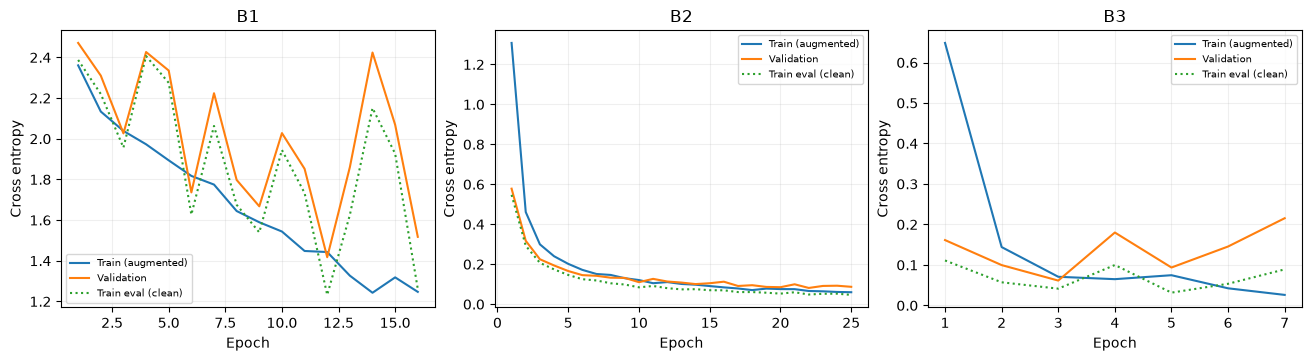

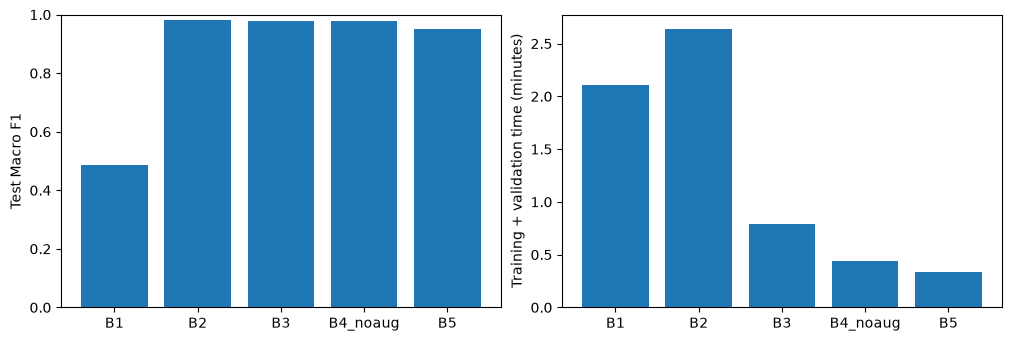

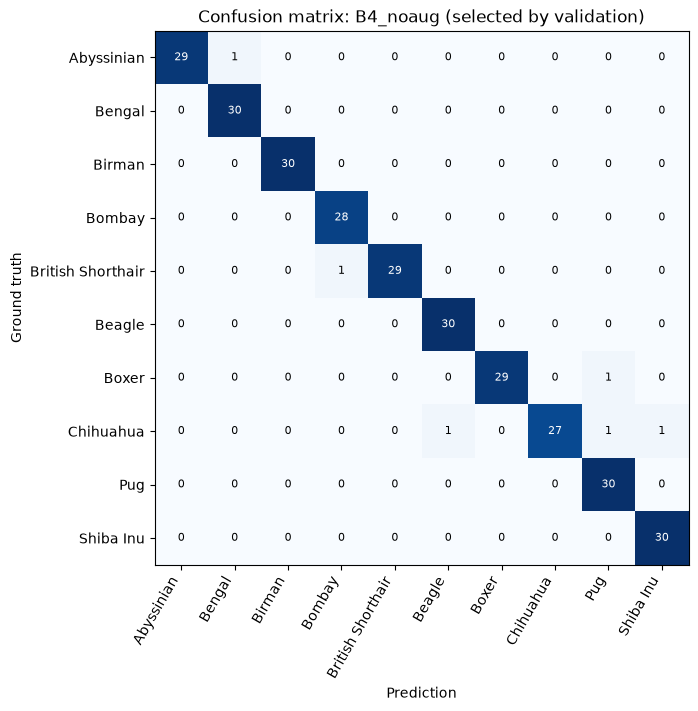

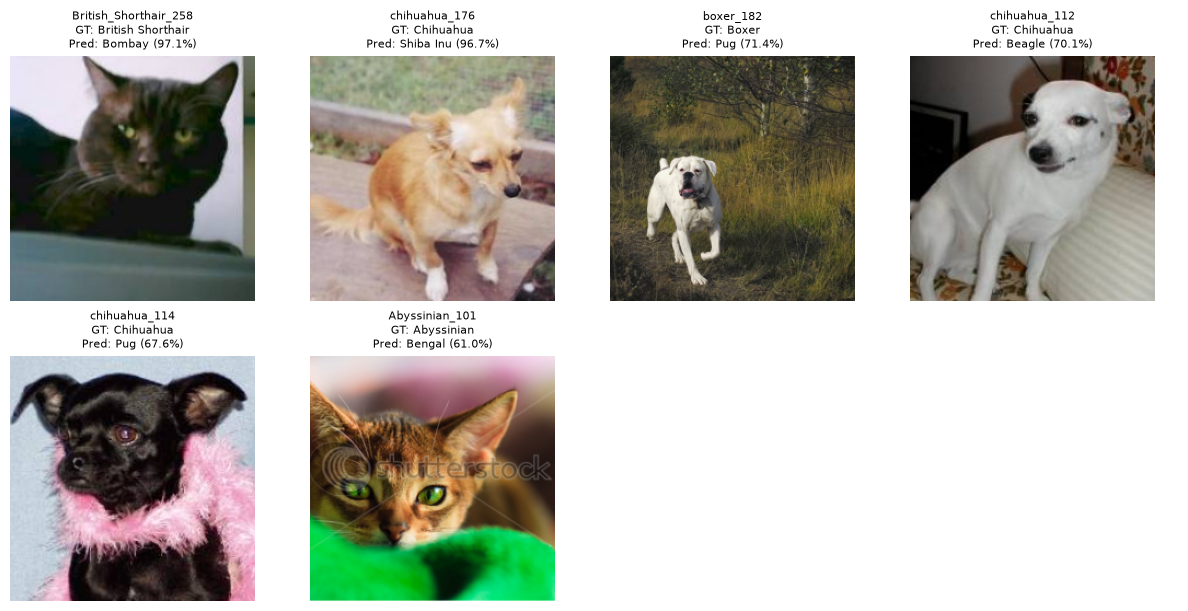

Model dipilih berdasarkan validation loss: B4_noaug


,image_id,truth,prediction,confidence,ground_truth,predicted_breed,hipotesis_mahasiswa
134,British_Shorthair_258,4,3,0.970906,British Shorthair,Bombay,
223,chihuahua_176,7,9,0.966969,Chihuahua,Shiba Inu,
190,boxer_182,6,8,0.714021,Boxer,Pug,
211,chihuahua_112,7,5,0.700871,Chihuahua,Beagle,
212,chihuahua_114,7,8,0.675597,Chihuahua,Pug,
1,Abyssinian_101,0,1,0.610216,Abyssinian,Bengal,


In [28]:
# - Tampilkan grafik dan gambar salah prediksi
failures = plot_results(results, best_model_name, cache)
display(failures)


## 29. Perbandingan Augmentasi

In [29]:
# - Bandingkan hasil dengan dan tanpa augmentasi
paired = metrics.set_index("code").loc[["B3", "B4_noaug"]]
comparison_columns = [
    "val_accuracy",
    "test_macro_f1",
    "train_eval_accuracy",
    "generalization_gap",
    "epochs_run",
]
display(paired[comparison_columns])
delta = {}
for metric_name in ["val_accuracy", "test_macro_f1", "generalization_gap"]:
    with_augmentation = paired.loc["B3", metric_name]
    without_augmentation = paired.loc["B4_noaug", metric_name]
    delta[metric_name] = float(with_augmentation - without_augmentation)  # - Selisih hasil dengan augmentasi dikurangi tanpa augmentasi
save_json(OUTPUT_DIR / "augmentation_delta.json", delta)
print("Delta dengan augmentasi - tanpa augmentasi:", delta)


,val_accuracy,test_macro_f1,train_eval_accuracy,generalization_gap,epochs_run
code,,,,,
B3,0.983165,0.979748,0.984848,0.001684,7
B4_noaug,0.983165,0.979754,1.000000,0.016835,10


Delta dengan augmentasi - tanpa augmentasi: {'val_accuracy': 0.0, 'test_macro_f1': -5.5632806171823646e-06, 'generalization_gap': -0.015151515151515138}


## 30. Verifikasi Gradien

In [30]:
# - Cek gradien dan statistik BatchNorm
def verify_model_configuration():
    seed_all()
    images = torch.randn(2, 3, 224, 224, device=DEVICE)
    labels = torch.tensor([0, 1], device=DEVICE)
    for strategy in ["scratch", "feature", "finetune"]:
        model, optimizer, trainable_parameters = build_model(strategy, pretrained=False)
        train_mode(model, strategy, "resnet18")
        running_mean_before = model.bn1.running_mean.clone()
        logits = model(images)  # - Hitung skor setiap kelas
        nn.functional.cross_entropy(logits, labels).backward()
        assert logits.shape == (2, 10)
        assert model.fc.weight.grad is not None
        assert (model.layer4[0].conv1.weight.grad is not None) == (
            strategy != "feature"
        )
        assert (model.conv1.weight.grad is not None) == (strategy == "scratch")
        if strategy != "scratch":
            assert torch.equal(running_mean_before, model.bn1.running_mean)
        optimizer.step()  # - Perbarui bobot yang aktif
        print(strategy, f"{trainable_parameters:,} trainable parameters: PASS")
        del model, optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print("Konfigurasi gradien dan BatchNorm sesuai protokol.")


## 31. Jalankan Verifikasi

In [31]:
# - Jalankan pengecekan model
verify_model_configuration()


scratch 11,181,642 trainable parameters: PASS
feature 5,130 trainable parameters: PASS


finetune 8,398,858 trainable parameters: PASS
Konfigurasi gradien dan BatchNorm sesuai protokol.


## 32. Audit Hasil

In [32]:
# - Cocokkan log dengan hasil prediksi
def audit_experiment_outputs():
    saved_results = json.loads(
        (OUTPUT_DIR / "metrics.json").read_text(encoding="utf-8")
    )
    expected = {"B1", "B2", "B3", "B4_noaug"} | (
        {"B5"} if CONFIG["run_bonus"] else set()
    )
    assert {result["code"] for result in saved_results} == expected
    manifest = pd.read_csv(OUTPUT_DIR / "split_manifest.csv")
    assert manifest.image_id.is_unique  # - Pastikan ID gambar tidak berulang
    assert manifest.groupby("sha256").split.nunique().max() == 1  # - Pastikan gambar yang sama tidak masuk split berbeda
    test_ids = set(manifest.loc[manifest.split == "test", "image_id"])
    for result in saved_results:
        history = pd.read_csv(OUTPUT_DIR / result["code"] / "history.csv")
        prediction = pd.read_csv(OUTPUT_DIR / result["code"] / "test_predictions.csv")
        assert len(history) == result["epochs_run"]
        best_epoch_metrics = history.loc[history.val_loss.idxmin()]
        assert int(best_epoch_metrics.epoch) == result["best_epoch"]
        assert np.isclose(best_epoch_metrics.val_accuracy, result["val_accuracy"])
        recomputed_f1 = f1_score(
            prediction.truth,
            prediction.prediction,
            labels=list(range(10)),
            average="macro",  # - Rata-rata F1 semua kelas dengan bobot sama
            zero_division=0,  # - Gunakan 0 jika pembagian metrik tidak terdefinisi
        )
        assert np.isclose(recomputed_f1, result["test_macro_f1"])
        assert prediction.image_id.is_unique and set(prediction.image_id) == test_ids
        assert np.isclose(
            result["generalization_gap"],
            result["train_eval_accuracy"] - result["val_accuracy"],
        )
        assert result["training_seconds"] >= history.epoch_seconds.sum()
        print(result["code"], "audit metrik dan prediksi: PASS")
    selected = json.loads((OUTPUT_DIR / "selection.json").read_text(encoding="utf-8"))
    assert (
        selected["best_code"]
        == min(saved_results, key=lambda result: (result["val_loss"], result["code"]))[
            "code"
        ]
    )
    assert selected["test_used_for_selection"] is False
    print("Audit selesai; pemilihan model menggunakan validation loss.")


## 33. Jalankan Audit

In [33]:
# - Jalankan pengecekan hasil
audit_experiment_outputs()


B1 audit metrik dan prediksi: PASS
B2 audit metrik dan prediksi: PASS
B3 audit metrik dan prediksi: PASS
B4_noaug audit metrik dan prediksi: PASS
B5 audit metrik dan prediksi: PASS
Audit selesai; pemilihan model menggunakan validation loss.


## 34. Import Ekspor

In [34]:
# - Import library untuk ekspor file
import zipfile
from IPython.display import FileLink, display


## 35. Ekspor ZIP

In [35]:
# - Save log dan grafik ke ZIP
def export_experiment_outputs(include_checkpoints=False):
    destination = Path("Tugas05_Hasil_GPU.zip")
    files = sorted(
        (
            path
            for path in OUTPUT_DIR.rglob("*")
            if path.is_file() and (include_checkpoints or path.suffix != ".pt")
        )
    )
    assert files, "Jalankan eksperimen sebelum membuat arsip."
    with zipfile.ZipFile(destination, "w", zipfile.ZIP_DEFLATED) as archive:
        for path in files:
            archive.write(path, arcname=str(path.relative_to(OUTPUT_DIR)))
    with zipfile.ZipFile(destination) as archive:
        assert archive.testzip() is None
    print(
        f"Arsip berisi {len(files)} berkas hasil. Checkpoint disertakan: {include_checkpoints}."
    )
    display(FileLink(str(destination)))
    return destination


## 36. Buat Arsip

In [36]:
# - Buat ZIP hasil eksperimen
result_archive = export_experiment_outputs()


Arsip berisi 36 berkas hasil. Checkpoint disertakan: False.


C:\Users\Luthfi\.vscode\VJudge.binus\Tugas\Deep Learning\Tugas05_Hasil_GPU.zip